NAME - Ujjawal chauhan
sec-'B' '62'
CU24250259
LABSHEET-07


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/sample_data/Mall_Customers.csv")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (200, 6)

Column Names:
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
 5   Cluster                 200 non-null    int32 
dtypes: int32(1), int64(4), object(1)
memory usage: 8.7+ KB


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
Cluster                   0
dtype: int64


In [ ]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())


Duplicates before: 0
Duplicates after: 0


In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Cluster
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000,2.195000
std,57.879185,13.969007,26.264721,25.823522,1.332612
min,1.000000,18.000000,15.000000,1.000000,0.000000
25%,50.750000,28.750000,41.500000,34.750000,1.000000
50%,100.500000,36.000000,61.500000,50.000000,2.000000
75%,150.250000,49.000000,78.000000,73.000000,3.000000
max,200.000000,70.000000,137.000000,99.000000,4.000000


In [ ]:
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

print("Selected Features:")
X.head()

Selected Features:


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")

Feature scaling completed!


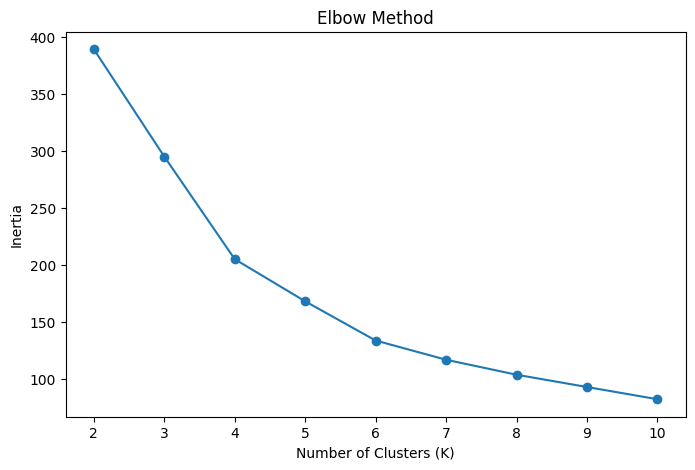

In [ ]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

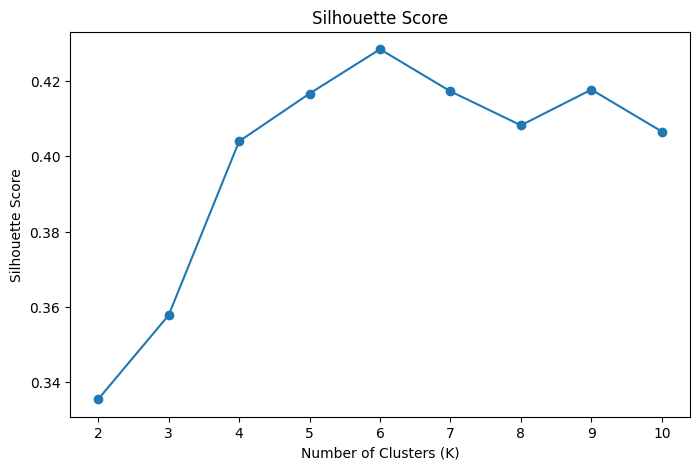

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.show()

In [ ]:
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("Best K according to Silhouette Score:", best_k)
print("Best Silhouette Score:", round(max(silhouette_scores), 3))

Best K according to Silhouette Score: 6
Best Silhouette Score: 0.428


In [ ]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

K-Means clustering completed!


In [ ]:
df.head(10)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,4
2,3,Female,20,16,6,5
3,4,Female,23,16,77,4
4,5,Female,31,17,40,5
5,6,Female,22,17,76,4
6,7,Female,35,18,6,5
7,8,Female,23,18,94,4
8,9,Male,64,19,3,5
9,10,Female,30,19,72,4


In [ ]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

centroid_df = pd.DataFrame(
    centroids,
    columns=[
        'Age',
        'Annual Income (k$)',
        'Spending Score (1-100)'
    ]
)

print("Cluster Centroids:")
centroid_df

Cluster Centroids:


,Age,Annual Income (k$),Spending Score (1-100)
0,56.333333,54.266667,49.066667
1,26.794872,57.102564,48.128205
2,41.939394,88.939394,16.969697
3,32.692308,86.538462,82.128205
4,25.000000,25.260870,77.608696
5,45.523810,26.285714,19.380952


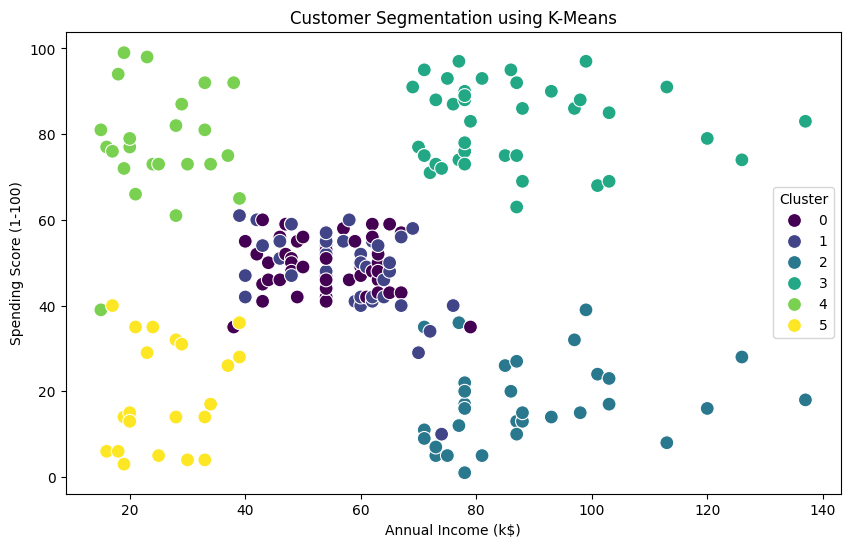

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [ ]:
cluster_analysis = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean()

cluster_analysis

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.333333,54.266667,49.066667
1,26.794872,57.102564,48.128205
2,41.939394,88.939394,16.969697
3,32.692308,86.538462,82.128205
4,25.000000,25.260870,77.608696
5,45.523810,26.285714,19.380952


In [ ]:
cluster_counts = df['Cluster'].value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

Number of customers in each cluster:
Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


In [ ]:
print("Customer Segmentation Results")
print("=" * 40)

for cluster in sorted(df['Cluster'].unique()):

    cluster_data = df[df['Cluster'] == cluster]

    print(f"\nCluster {cluster}")
    print("-" * 20)
    print("Number of Customers:", len(cluster_data))
    print("Average Age:", round(cluster_data['Age'].mean(), 2))
    print("Average Income:",
          round(cluster_data['Annual Income (k$)'].mean(), 2), "k$")
    print("Average Spending Score:",
          round(cluster_data['Spending Score (1-100)'].mean(), 2))

Customer Segmentation Results

Cluster 0
--------------------
Number of Customers: 45
Average Age: 56.33
Average Income: 54.27 k$
Average Spending Score: 49.07

Cluster 1
--------------------
Number of Customers: 39
Average Age: 26.79
Average Income: 57.1 k$
Average Spending Score: 48.13

Cluster 2
--------------------
Number of Customers: 33
Average Age: 41.94
Average Income: 88.94 k$
Average Spending Score: 16.97

Cluster 3
--------------------
Number of Customers: 39
Average Age: 32.69
Average Income: 86.54 k$
Average Spending Score: 82.13

Cluster 4
--------------------
Number of Customers: 23
Average Age: 25.0
Average Income: 25.26 k$
Average Spending Score: 77.61

Cluster 5
--------------------
Number of Customers: 21
Average Age: 45.52
Average Income: 26.29 k$
Average Spending Score: 19.38


In [ ]:
print("""
Conclusion:
K-Means Clustering was successfully applied to the Mall Customers
dataset. Customers were segmented based on Age, Annual Income,
and Spending Score. The Elbow Method and Silhouette Score were
used to determine a suitable number of clusters. The resulting
customer segments can help businesses understand customer
behavior and develop targeted marketing strategies.
""")


Conclusion:
K-Means Clustering was successfully applied to the Mall Customers
dataset. Customers were segmented based on Age, Annual Income,
and Spending Score. The Elbow Method and Silhouette Score were
used to determine a suitable number of clusters. The resulting
customer segments can help businesses understand customer
behavior and develop targeted marketing strategies.

